In [3]:
import pandas as pd
import networkx as nx
from matplotlib.pyplot import figure
# import dask.dataframe as dd

datasets = ["concept_ancestor", "concept_relationship", "concept", "condition_occurrence", "death", "drug_exposure", "measurement", "observation", "person", "procedure_occurrence", "relationship", "visit_occurrence", "vocabulary"]

person = pd.read_csv("ehrshot/person.csv")
concept_ancestor = pd.read_csv("ehrshot/concept_ancestor.csv")
concept_relationship = pd.read_csv("ehrshot/concept_relationship.csv")
concept = pd.read_csv("ehrshot/concept.csv")
condition_occurrence = pd.read_csv("ehrshot/condition_occurrence.csv")
death = pd.read_csv("ehrshot/death.csv")
drug_exposure = pd.read_csv("ehrshot/drug_exposure.csv")
measurement = pd.read_csv("ehrshot/measurement.csv")
observation = pd.read_csv("ehrshot/observation.csv")
procedure_occurrence = pd.read_csv("ehrshot/procedure_occurrence.csv")
relationship = pd.read_csv("ehrshot/relationship.csv")
visit_occurrence = pd.read_csv("ehrshot/visit_occurrence.csv")
vocabulary = pd.read_csv("ehrshot/vocabulary.csv")

C:\Users\duxed\AppData\Local\Temp\ipykernel_21996\2141916293.py:11: DtypeWarning: Columns (9: invalid_reason) have mixed types. Specify dtype option on import or set low_memory=False.
  concept = pd.read_csv("ehrshot/concept.csv")
C:\Users\duxed\AppData\Local\Temp\ipykernel_21996\2141916293.py:12: DtypeWarning: Columns (5: condition_end_DATE, 6: condition_end_DATETIME, 14: condition_status_source_value) have mixed types. Specify dtype option on import or set low_memory=False.
  condition_occurrence = pd.read_csv("ehrshot/condition_occurrence.csv")
C:\Users\duxed\AppData\Local\Temp\ipykernel_21996\2141916293.py:14: DtypeWarning: Columns (18: drug_source_value) have mixed types. Specify dtype option on import or set low_memory=False.
  drug_exposure = pd.read_csv("ehrshot/drug_exposure.csv")
C:\Users\duxed\AppData\Local\Temp\ipykernel_21996\2141916293.py:16: DtypeWarning: Columns (14: unit_source_value) have mixed types. Specify dtype option on import or set low_memory=False.
  observati

In [4]:
disease_target = concept.loc[concept['concept_id']== 317576]['concept_name']

print(disease_target.to_string())

8056526    Coronary arteriosclerosis


In [5]:
# condition_occurrence.info()

chd_occurrence = condition_occurrence.loc[condition_occurrence['condition_concept_id']==317576]

chd_occurrence.info()

# print(chd_occurrence.to_string())

<class 'pandas.DataFrame'>
Index: 2628 entries, 22807 to 2565414
Data columns (total 19 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   condition_occurrence_id        2628 non-null   int64  
 1   person_id                      2628 non-null   int64  
 2   condition_concept_id           2628 non-null   int64  
 3   condition_start_DATE           2628 non-null   str    
 4   condition_start_DATETIME       2628 non-null   str    
 5   condition_end_DATE             22 non-null     str    
 6   condition_end_DATETIME         22 non-null     str    
 7   condition_type_concept_id      2628 non-null   int64  
 8   stop_reason                    0 non-null      float64
 9   provider_id                    1385 non-null   float64
 10  visit_occurrence_id            2293 non-null   float64
 11  visit_detail_id                0 non-null      float64
 12  condition_source_value         2628 non-null   str    
 1

In [6]:
#visit_occurrence.info()
#person.info()
person_to_visit = visit_occurrence.merge(person, "inner", 'person_id')

person_to_visit.info()


<class 'pandas.DataFrame'>
RangeIndex: 944132 entries, 0 to 944131
Data columns (total 40 columns):
 #   Column                         Non-Null Count   Dtype  
---  ------                         --------------   -----  
 0   visit_occurrence_id            944132 non-null  int64  
 1   person_id                      944132 non-null  int64  
 2   visit_concept_id               944132 non-null  int64  
 3   visit_start_DATE               944132 non-null  str    
 4   visit_start_DATETIME           944132 non-null  str    
 5   visit_end_DATE                 944132 non-null  str    
 6   visit_end_DATETIME             944132 non-null  str    
 7   visit_type_concept_id          944132 non-null  int64  
 8   provider_id_x                  901544 non-null  float64
 9   care_site_id_x                 933877 non-null  float64
 10  visit_source_value             944132 non-null  str    
 11  visit_source_concept_id        944132 non-null  int64  
 12  admitting_source_concept_id    944132 non

In [7]:
chd_visits = person_to_visit.merge(chd_occurrence, "inner", 'person_id')

chd_visits = chd_visits.loc[chd_visits['condition_concept_id']==317576]

chd_visits.info()

<class 'pandas.DataFrame'>
RangeIndex: 1034457 entries, 0 to 1034456
Data columns (total 58 columns):
 #   Column                         Non-Null Count    Dtype  
---  ------                         --------------    -----  
 0   visit_occurrence_id_x          1034457 non-null  int64  
 1   person_id                      1034457 non-null  int64  
 2   visit_concept_id               1034457 non-null  int64  
 3   visit_start_DATE               1034457 non-null  str    
 4   visit_start_DATETIME           1034457 non-null  str    
 5   visit_end_DATE                 1034457 non-null  str    
 6   visit_end_DATETIME             1034457 non-null  str    
 7   visit_type_concept_id          1034457 non-null  int64  
 8   provider_id_x                  984686 non-null   float64
 9   care_site_id_x                 1013114 non-null  float64
 10  visit_source_value             1034457 non-null  str    
 11  visit_source_concept_id        1034457 non-null  int64  
 12  admitting_source_concept_

In [8]:
vocabulary.info()

<class 'pandas.DataFrame'>
RangeIndex: 138 entries, 0 to 137
Data columns (total 7 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   vocabulary_id          137 non-null    str    
 1   vocabulary_name        138 non-null    str    
 2   vocabulary_reference   138 non-null    str    
 3   vocabulary_version     75 non-null     str    
 4   vocabulary_concept_id  138 non-null    int64  
 5   load_table_id          138 non-null    str    
 6   load_row_id            0 non-null      float64
dtypes: float64(1), int64(1), str(5)
memory usage: 7.7 KB


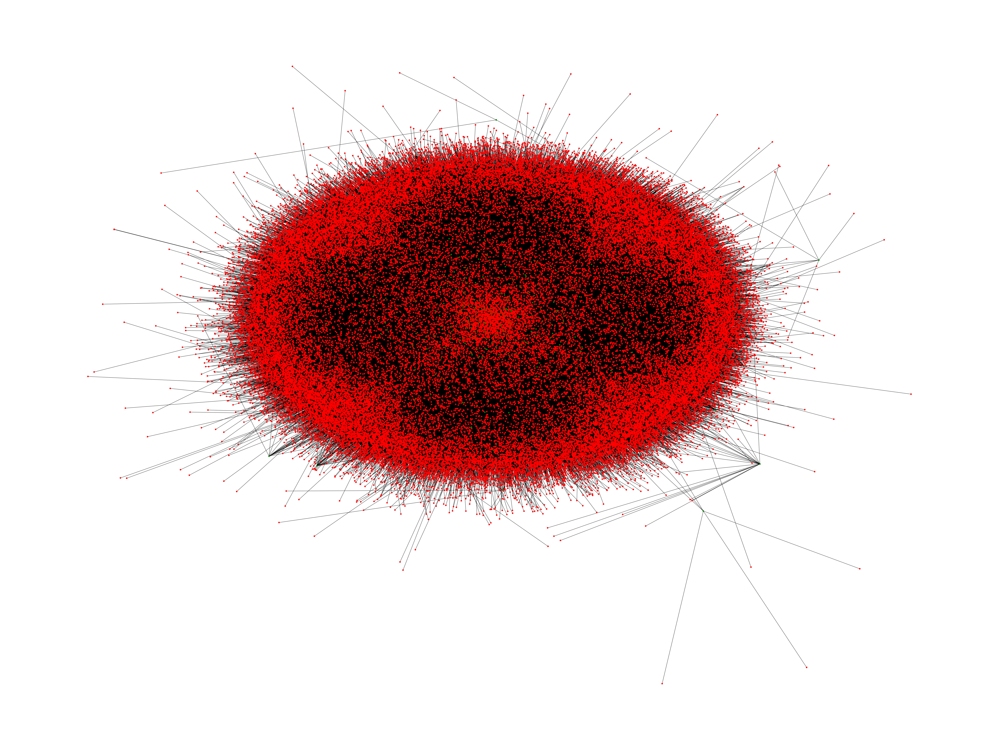

In [12]:
chd_visits_edgelist = chd_visits[['person_id', 'visit_start_DATETIME']]

G = nx.from_pandas_edgelist(chd_visits_edgelist, 'person_id', 'visit_start_DATETIME')

people_nodes = set(chd_visits_edgelist['person_id'])
visit_nodes = set(chd_visits_edgelist['visit_start_DATETIME'])

nodes = G.nodes()
colors = ['green' if node in people_nodes else 'red' for node in nodes]

figure(figsize=(64, 48))
nx.draw(G, with_labels=False, node_size=35, node_color = colors)

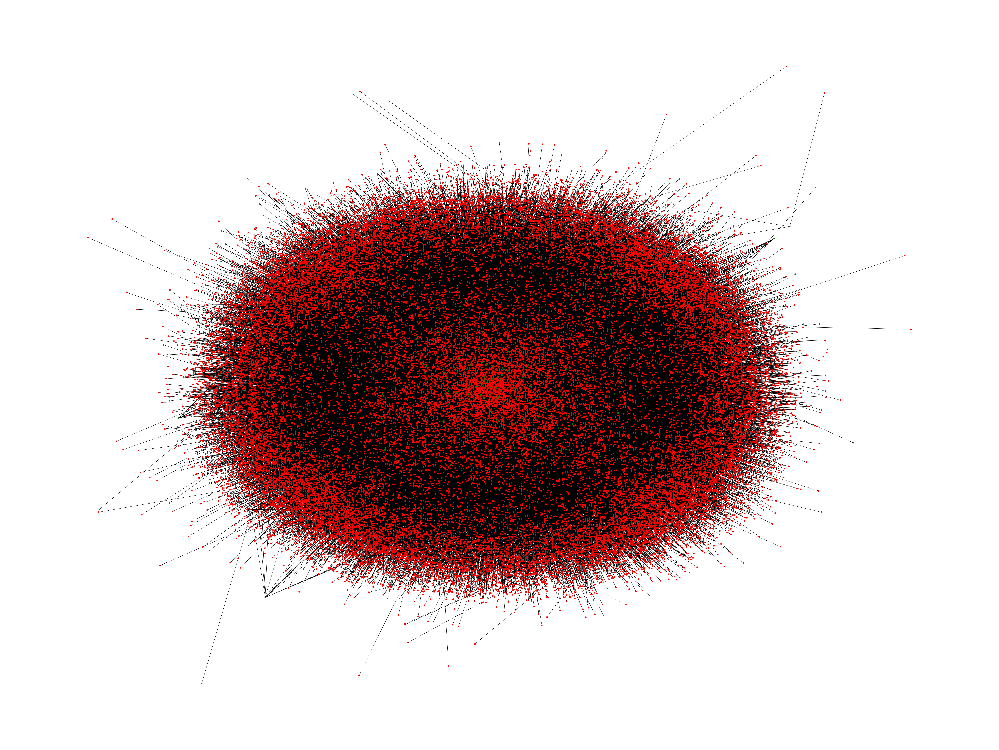

In [13]:
chd_visits_men = chd_visits.loc[chd_visits['gender_concept_id'] == 8507]
chd_visits_women = chd_visits.loc[chd_visits['gender_concept_id'] == 8532]

chd_visits_edgelist_men = chd_visits_men[['person_id', 'visit_start_DATETIME']]

Gman = nx.from_pandas_edgelist(chd_visits_edgelist_men, 'person_id', 'visit_start_DATETIME')

people_nodes_men = set(chd_visits_edgelist_men['person_id'])
visit_nodes_men = set(chd_visits_edgelist_men['visit_start_DATETIME'])

nodes_men = Gman.nodes()
colors_men = ['green' if node in people_nodes_men else 'red' for node in nodes_men]

figure(figsize=(64, 48))
nx.draw(Gman, with_labels=False, node_size=35, node_color = colors_men)

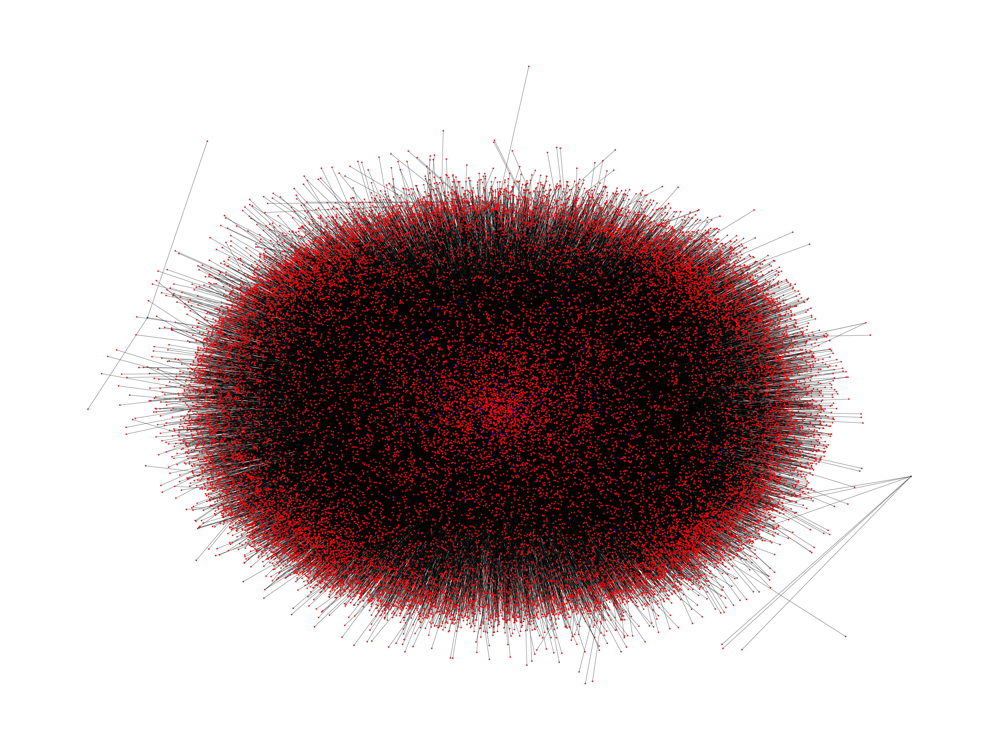

In [14]:
chd_visits_edgelist_women = chd_visits_women[['person_id', 'visit_start_DATETIME']]

Gwoman = nx.from_pandas_edgelist(chd_visits_edgelist_women, 'person_id', 'visit_start_DATETIME')

people_nodes_women = set(chd_visits_edgelist_women['person_id'])
visit_nodes_women = set(chd_visits_edgelist_women['visit_start_DATETIME'])

nodes_women = Gwoman.nodes()
colors_women = ['blue' if node in people_nodes_women else 'red' for node in nodes_women]

figure(figsize=(64, 48))
nx.draw(Gwoman, with_labels=False, node_size=35, node_color = colors_women)

In [16]:
print(Gman.number_of_nodes(), Gman.number_of_edges())

41203 70415


In [17]:
print(Gwoman.number_of_nodes(), Gwoman.number_of_edges())

28107 43268


In [23]:
print(nx.density(Gman))
print(nx.density(Gwoman))
print(nx.density(G))

8.295604590254017e-05
0.00010954265962392532
5.8430787923984475e-05


In [24]:
print(nx.average_clustering(Gman))
print(nx.average_clustering(Gwoman))
print(nx.average_clustering(G))

0.0
0.0
0.0


In [ ]:
print(nx.degree_centrality(Gman))
print(nx.degree_centrality(Gwoman))